<a href="https://colab.research.google.com/github/jfemiani/cse620b-public/blob/main/labs/harvard-forest-lai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Can satellites tell how leafy a forest is?

**Ungraded in-class lab · 25–30 minutes · Work in small groups**

Compare satellite images of Harvard Forest with measurements of leaf area taken on the ground. Your group will calculate one optical index and one radar index, then test how well each predicts leaf area on three visits in 2024.

Run the setup and image cells first. Write your own code in the two **Your turn** cells. If you want to check your work, use the [worked key](https://colab.research.google.com/github/jfemiani/cse620b-public/blob/ee3304484edb712181b59f23f4fbd9c8d3962122/labs/harvard-forest-lai.ipynb) after class.

## 1. Download the data

The ZIP contains small satellite images with the original bands on a common 20 m grid. The CSV contains the field measurements.

In [5]:
%%bash
set -e
wget -nv -O harvard-forest-chips.zip https://vision.csi.miamioh.edu/data/cse620b/forestry/harvard-forest-chips.zip
unzip -oq harvard-forest-chips.zip -d harvard-forest
wget -nv -O lai.csv https://harvardforest1.fas.harvard.edu/data/p06/hf069/hf069-02-lai-site.csv

2026-11-18 16:23:54 URL:https://vision.csi.miamioh.edu/data/cse620b/forestry/harvard-forest-chips.zip [957614/957614] -> "harvard-forest-chips.zip" [1]
2026-11-18 16:23:55 URL:https://harvardforest1.fas.harvard.edu/data/p06/hf069/hf069-02-lai-site.csv [22982/22982] -> "lai.csv" [1]


## 2. Find the study area

These color views show the same 1.2 km-wide area at Harvard Forest's Prospect Hill tract in Massachusetts. The white outline marks the approximate field survey area, where transects run west of the Environmental Measurement Site (EMS) tower. It covers roughly the western half of a 500 m radius around the tower.

**Look first.** Where does the forest change most between June and November? Which changes might a radar image pick up?

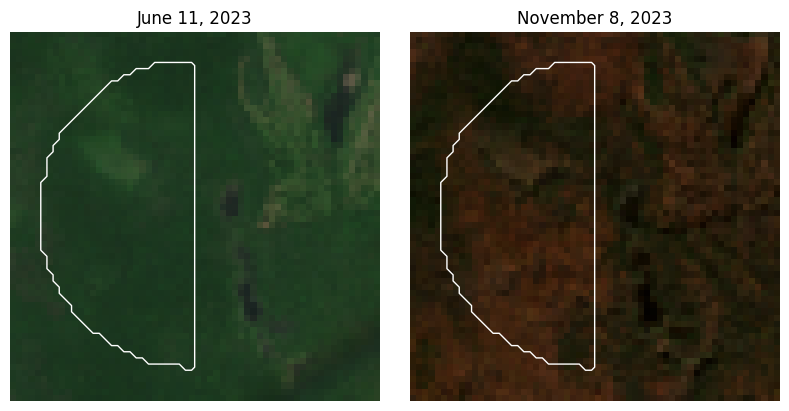

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

footprint = np.load("harvard-forest/footprint.npy")

def load_bands(visit):
    with np.load(f"harvard-forest/{visit}.npz") as chip:
        return dict(chip)

def show_rgb(ax, bands):
    rgb = np.dstack([bands["B04"], bands["B03"], bands["B02"]])
    ax.imshow(np.clip(rgb * 4, 0, 1))
    ax.contour(footprint, levels=[0.5], colors="white", linewidths=1)
    ax.set_axis_off()

fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
for ax, visit, label in zip(
    axes,
    ["2023-06-05", "2023-11-07"],
    ["June 11, 2023", "November 8, 2023"],
):
    show_rgb(ax, load_bands(visit))
    ax.set_title(label)
plt.show()

## 3. Read and display the source bands

Each band is a 2D array. Sentinel-2 values are surface reflectance. Sentinel-1 values are linear radar backscatter power. This radar series has **VV** and **VH**. The letters give the transmit and receive polarizations, respectively. **HH** (horizontal transmit and receive) and **HV** are other possible channels. The archive does not carry them.

Run the cell to see each band and the values of one pixel. The color scale is set separately for each band. Use its colorbar when comparing values. Try changing the visit to `"2023-11-07"`. What changes in red and near-infrared? What changes in VV and VH?

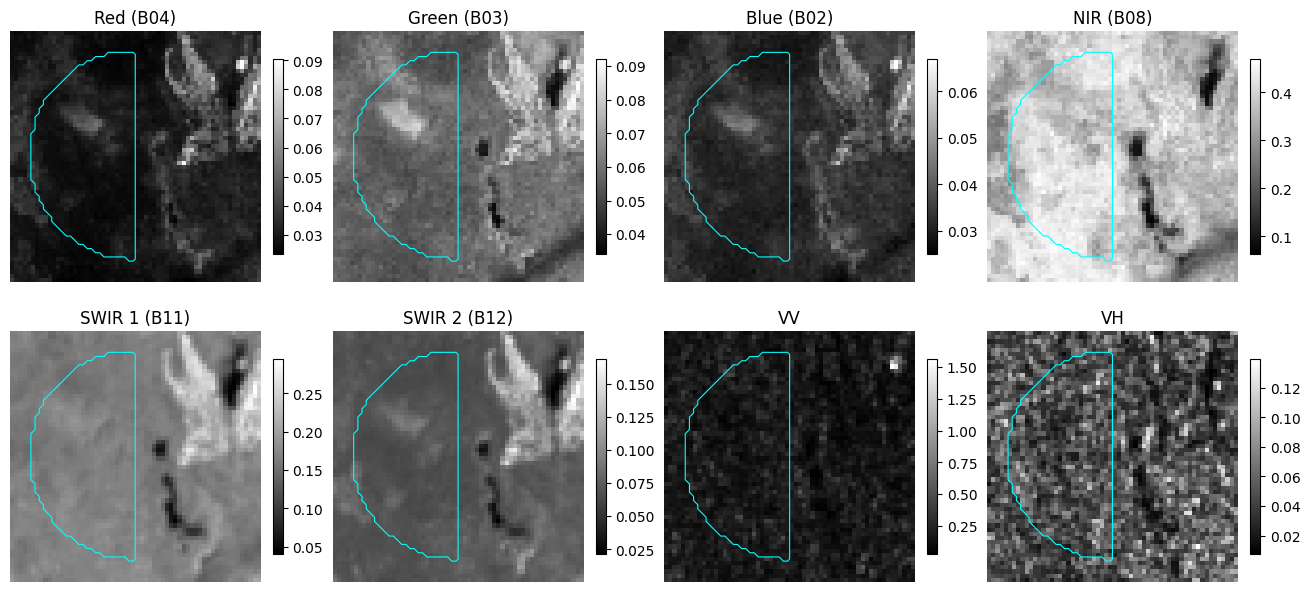

Pixel at row 30, column 20
Red (B04): 0.0285
Green (B03): 0.0563
Blue (B02): 0.0318
NIR (B08): 0.4220
SWIR 1 (B11): 0.1717
SWIR 2 (B12): 0.0717
VV: 0.1531
VH: 0.0195


In [7]:
visit = "2023-06-05"  # Date of the field visit used to name the image file
bands = load_bands(visit)
band_names = {
    "Red (B04)": "B04", "Green (B03)": "B03", "Blue (B02)": "B02",
    "NIR (B08)": "B08", "SWIR 1 (B11)": "B11", "SWIR 2 (B12)": "B12",
    "VV": "VV", "VH": "VH",
}

fig, axes = plt.subplots(2, 4, figsize=(13, 6), layout="constrained")
for ax, (label, band) in zip(axes.flat, band_names.items()):
    image = ax.imshow(bands[band], cmap="gray")
    ax.contour(footprint, levels=[0.5], colors="cyan", linewidths=0.8)
    ax.set_title(label)
    ax.set_axis_off()
    fig.colorbar(image, ax=ax, shrink=0.7)
plt.show()

row, col = 30, 20
print(f"Pixel at row {row}, column {col}")
for label, band in band_names.items():
    print(f"{label}: {bands[band][row, col]:.4f}")

## 4. Match satellite images to field measurements

**Leaf area index (LAI)** is leaf area per unit of ground area. The table gives the mean LAI across the plots measured on each field visit and the dates of the paired optical and radar images. A field visit gives you one LAI value. To compare it with an index map, you will need to reduce the pixels to one index value for that visit.

Find the June and November visits. Do the measured LAI values agree with your impression from the color images?

In [8]:
field = pd.read_csv("lai.csv")
field = field.loc[field["site"] == "ems", ["date", "n_plots", "all_mean"]]
field = field.rename(columns={"date": "field_date", "all_mean": "LAI"})
scenes = pd.read_csv("harvard-forest/scenes.csv")
visits = scenes.merge(field, on="field_date", validate="one_to_one")
display(visits[["field_date", "optical_date", "radar_date", "n_plots", "LAI"]])

def usable_pixels(bands):
    # Class 4 means vegetation in the Sentinel-2 scene classification.
    valid = footprint & (bands["SCL"] == 4)
    for band in band_names.values():
        valid &= np.isfinite(bands[band]) & (bands[band] > 0)
    return valid

,field_date,optical_date,radar_date,n_plots,LAI
0,2022-05-11,2022-05-12,2022-05-05,33,1.67
1,2022-05-27,2022-06-06,2022-05-29,33,4.20
2,2022-06-17,2022-06-26,2022-06-22,33,4.45
3,2022-07-15,2022-07-11,2022-07-16,33,4.71
4,2022-08-28,2022-08-30,2022-09-02,31,4.52
5,2023-05-10,2023-05-12,2023-05-12,33,2.20
6,2023-06-05,2023-06-11,2023-06-05,33,3.90
7,2023-10-10,2023-10-09,2023-10-03,33,3.79
8,2023-11-07,2023-11-08,2023-11-08,33,2.14
9,2024-05-30,2024-05-31,2024-05-30,32,4.10


## 5. Your turn · Calculate two indices

1. Pick one optical index and one radar index. For example, start with NDVI and a ratio of the two radar channels. Write down the formulas your group chose.
2. Implement the formulas with the source arrays. Make a map of each index for one visit. Use `usable_pixels(bands)` to keep the same pixels in both maps. Use `np.nan` for masked pixels when plotting.
3. Repeat for every date in `visits["field_date"]`. For each index, take the median over the usable pixels. Add the two summaries as columns in a copy of `visits`, with one row per visit.

The index maps will look roughly semicircular when you mask them. The cyan outline in the source-band plots shows where that shape comes from. Gaps inside it are pixels that fail the vegetation or validity checks.

In [9]:
# Write your code here.
# Start with the bands from one visit and check the two index maps.
# Then build a table with both index summaries and LAI for each visit.

## 6. Your turn · Fit and test your models

1. Use the **2022–2023** rows to fit a separate line for each index. Use the index as x and measured LAI as y. Estimate the slope and intercept for each line. Hint: `np.polyfit` with degree 1 fits a straight line.
2. Use each fitted line to predict LAI from the index values for the three **2024** visits. Put the two predictions and measured LAI side by side for each date.
3. Compare the models' root mean squared errors (RMSE) with a baseline that predicts the 2022–2023 mean LAI for every 2024 visit. Keep the 2024 rows out of the fitting step.

In [10]:
# Write your code here.
# Split the visits by year, fit two lines, and compare their predictions
# with measured LAI and the baseline on the three 2024 visits.

## Share your results

Tell another group which indices you chose and whether either model beat the baseline. Which visit was hardest to predict? Check how far apart the field and satellite dates were. How could rapid leaf-out or a wet canopy affect the result?

All three test dates come from the same forest. What measurements would you need to test whether either index can distinguish two stands with different LAI on the same day?

## Data and worked examples


- [Harvard Forest HF069: Biomass Inventories at the EMS Tower](https://harvardforest1.fas.harvard.edu/exist/apps/datasets/showData.html?id=hf069).
  Uses the `ems` rows of the published site LAI table, not a gridded LAI product.
- Contains modified Copernicus Sentinel data (2022–2024), retrieved through
  [Sentinel-2 L2A](https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a)
  and [Sentinel-1 RTC](https://planetarycomputer.microsoft.com/dataset/sentinel-1-rtc).
- [Rasterio walk-through for Sentinel-2 NDVI](https://www.forestry-ecological-gis.org/ecological-gis-data-foundations-in-python/vegetation-index-calculation-in-python/calculating-ndvi-from-sentinel-2-with-rasterio/),
  including surface-reflectance offsets and masked pixels.
- [Planetary Computer Sentinel-1 RTC tutorial](https://github.com/microsoft/PlanetaryComputerExamples/blob/main/tutorials/customizable-rtc-sentinel1.ipynb).
- [ESA PhiLab radar index examples](https://github.com/ESA-PhiLab/sarpyx/blob/main/docs/user_guide/science_applications.md).